# LoRA Batch vs Step Count Experiment (SDXL)

This notebook automates the full experiment pipeline described in the repository README:

- Prepare the Kohya `sd-scripts` training stack for SDXL LoRA.
- Iterate over all 15 dataset/batch/step configurations.
- Generate evaluation images for each trained LoRA using shared prompts.
- Compute CLIP, LPIPS, FID, intra-set diversity, and a simple overfitting proxy.
- Store every artifact (logs, weights, generations, metrics) back into Google Drive.

> **Tip:** Run each section sequentially. Use the `RUN_FILTER` control (later) to target a subset when debugging.

In [ ]:
!nvidia-smi

Sun Nov 30 05:13:20 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   36C    P0             53W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## Install dependencies

In [ ]:
%%bash
set -e

cd /usr/local/lib/python3.12/dist-packages
rm -rf ~orch ~torch ~torchvision* ~vidia-cudnn-cu12 2>/dev/null || true
cd -

python -m pip uninstall -y tensorflow-cpu jax jaxlib flax ml-dtypes >/dev/null 2>&1 || true
python -m pip install --upgrade pip setuptools wheel

pip install --quiet --upgrade \
  torch==2.4.1+cu121 torchvision==0.19.1+cu121 torchaudio==2.4.1+cu121 \
  --index-url https://download.pytorch.org/whl/cu121

pip install --quiet \
  numpy==1.26.4 pandas==2.2.3 opencv-python-headless==4.9.0.80 accelerate==0.30.1 \
  transformers==4.44.0 diffusers==0.30.0 safetensors==0.4.4 bitsandbytes==0.45.0 \
  peft==0.13.2 open-clip-torch==2.24.0 lpips==0.1.4 torchmetrics==1.4.2 \
  torch-fidelity==0.3.0 clean-fid==0.1.35 seaborn==0.13.2 matplotlib==3.9.2 \
  tqdm==4.66.5 einops==0.8.0 scikit-image==0.24.0 compel==2.0.3 ml-dtypes==0.4.0

pip install --quiet --extra-index-url https://download.pytorch.org/whl/cu121 \
  xformers==0.0.28.post2

/content


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
xformers 0.0.27.post2 requires torch==2.4.0, but you have torch 2.4.1+cu121 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorstore 0.1.79 requires ml_dtypes>=0.5.0, but you have ml-dtypes 0.4.0 which is incompatible.
tensorflow 2.19.0 requires ml-dtypes<1.0.0,>=0.5.1, but you have ml-dtypes 0.4.0 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchaudio 2.4.1+cu121 requires torch==2.4.1, but you have torch 2.5.0+cu121 which is incompatible.
torchvision 0.19.1+cu121 requires torch==2.4.1, but you have torch 2.5.0+c

In [ ]:
!python -m pip install --quiet compel==2.0.3

In [ ]:
# Disable TensorFlow auto-imports so diffusers/transformers stay PyTorch-only
import os
os.environ["TRANSFORMERS_NO_TF"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

In [ ]:
%%bash
pip install -q --upgrade --extra-index-url https://download.pytorch.org/whl/cu121 xformers==0.0.27.post2

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchaudio 2.4.1+cu121 requires torch==2.4.1, but you have torch 2.4.0+cu121 which is incompatible.
torchvision 0.19.1+cu121 requires torch==2.4.1, but you have torch 2.4.0+cu121 which is incompatible.


In [ ]:
import os, yaml, pathlib

cfg = {
    "compute_environment": "LOCAL_MACHINE",
    "distributed_type": "NO",
    "mixed_precision": "fp16",
    "use_cpu": False,
    "machine_rank": 0,
    "num_machines": 1,
    "num_processes": 1
}

config_path = pathlib.Path.home() / ".cache/huggingface/accelerate/default_config.yaml"
config_path.parent.mkdir(parents=True, exist_ok=True)

with open(config_path, "w") as f:
    yaml.safe_dump(cfg, f)

print(f"Wrote Accelerate config to {config_path}")

Wrote Accelerate config to /root/.cache/huggingface/accelerate/default_config.yaml


In [ ]:
%%bash
if [ ! -d sd-scripts ]; then
  git clone --depth 1 https://github.com/kohya-ss/sd-scripts.git
fi
cd sd-scripts
pip install -q --no-deps -r requirements.txt

## Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


## Config: core paths & constants

In [ ]:
import os, json, math, random, subprocess, textwrap, itertools, gc, shutil
from pathlib import Path
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
import torch
from PIL import Image

PROJECT_ROOT = Path('/content/drive/My Drive/LoRA Project Megafolder')
BASE_MODEL_PATH = PROJECT_ROOT / 'base_models' / 'illustriousXL_v01.safetensors'
TRAIN_SETS_DIR = PROJECT_ROOT / 'train_sets'
PROMPTS_PATH = PROJECT_ROOT / 'prompts' / 'test_prompts.json'
REFERENCE_DIR = PROJECT_ROOT / 'reference_set'
EXISTING_LORAS_DIR = PROJECT_ROOT / 'loras'
OUTPUT_ROOT = PROJECT_ROOT / 'outputs'
TRAIN_EXPORT_DIR = OUTPUT_ROOT / 'loras'
GENERATION_DIR = OUTPUT_ROOT / 'generations'
METRICS_DIR = OUTPUT_ROOT / 'metrics'

for p in [PROJECT_ROOT, BASE_MODEL_PATH, TRAIN_SETS_DIR, PROMPTS_PATH, REFERENCE_DIR]:
    if not p.exists():
        raise FileNotFoundError(f"Missing required path: {p}")

TRAIN_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
GENERATION_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

WORK_DIR = Path('/content/sd-scripts')
assert WORK_DIR.exists(), 'sd-scripts repo missing'

TARGET_RESOLUTION = '2047,2047'  # adjust if Colab VRAM is insufficient
NUM_CPU_THREADS = 2
BASE_SEED = 1337
DEVICE = 'cuda'
MIXED_PRECISION = 'fp16'
TRAIN_COMMENT = 'Milestone3_batch_vs_steps'
LORA_DIM = 32
LORA_ALPHA = 16
UNET_LR = 1.2e-4
TEXT_LR = 5.0e-5
LR_SCHED = 'cosine_with_restarts'
LR_CYCLES = 3

print('Base model:', BASE_MODEL_PATH)
print('Output dir:', OUTPUT_ROOT)

Base model: /content/drive/My Drive/LoRA Project Megafolder/base_models/illustriousXL_v01.safetensors
Output dir: /content/drive/My Drive/LoRA Project Megafolder/outputs


In [ ]:
# Determinism + environment snapshot
import sys
def set_global_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_global_seed(BASE_SEED)
freeze_txt = subprocess.check_output(["pip", "freeze"]).decode("utf-8")
env_path = OUTPUT_ROOT / "environment.txt"
with open(env_path, "w", encoding="utf-8") as f:
    f.write(freeze_txt)
print(f"Global seed fixed at {BASE_SEED}; pip freeze saved to {env_path}")

Global seed fixed at 1337; pip freeze saved to /content/drive/My Drive/LoRA Project Megafolder/outputs/environment.txt


## Build experiment grid

In [ ]:
dataset_plan = [
    {'size': 400, 'dir': '400 - data', 'epochs': 25},
    {'size': 200, 'dir': '200 - data', 'epochs': 50},
    {'size': 100, 'dir': '100 - data', 'epochs': 100},
    {'size': 50,  'dir': '50 - data',  'epochs': 200},
    {'size': 25,  'dir': '25 - data',  'epochs': 400}
]

batch_step_map = {
    4: 2500,
    2: 5000,
    1: 10000
}

experiment_grid = []
run_idx = 1
for block in dataset_plan:
    for batch, steps in batch_step_map.items():
        experiment_grid.append({
            'run_id': f'run_{run_idx:02d}',
            'train_set': block['dir'],
            'data_size': block['size'],
            'epochs': block['epochs'],
            'batch_size': batch,
            'max_steps': steps,
            'lora_name': f"kissshot_sz{block['size']}_bs{batch}_st{steps}",
        })
        run_idx += 1

grid_df = pd.DataFrame(experiment_grid)
grid_df

,run_id,train_set,data_size,epochs,batch_size,max_steps,lora_name
0,run_01,400 - data,400,25,4,2500,kissshot_sz400_bs4_st2500
1,run_02,400 - data,400,25,2,5000,kissshot_sz400_bs2_st5000
2,run_03,400 - data,400,25,1,10000,kissshot_sz400_bs1_st10000
3,run_04,200 - data,200,50,4,2500,kissshot_sz200_bs4_st2500
4,run_05,200 - data,200,50,2,5000,kissshot_sz200_bs2_st5000
5,run_06,200 - data,200,50,1,10000,kissshot_sz200_bs1_st10000
6,run_07,100 - data,100,100,4,2500,kissshot_sz100_bs4_st2500
7,run_08,100 - data,100,100,2,5000,kissshot_sz100_bs2_st5000
8,run_09,100 - data,100,100,1,10000,kissshot_sz100_bs1_st10000
9,run_10,50 - data,50,200,4,2500,kissshot_sz50_bs4_st2500


## Helper functions

In [ ]:
# === Helper functions (updated to reuse finished LoRAs) ===
EXISTING_LORAS_DIR = PROJECT_ROOT / 'loras'
DEFAULT_IMAGES_PER_PROMPT = 8  # 5 prompts × 8 seeds = 40 generations/run
GLOBAL_NEGATIVE_PROMPT = (
    "bad anatomy, extra limbs, extra fingers, mutated hands, deformed, ugly, blurry, "
    "lowres, text, watermark, signature, username, monochrome"
)

def ensure_lora_available(cfg):
    """
    Returns (lora_path, found_flag).
    Copies pre-trained files from `loras/` when present so we can skip training.
    """
    run_dir = (TRAIN_EXPORT_DIR / cfg['run_id']).resolve()
    run_dir.mkdir(parents=True, exist_ok=True)
    lora_path = run_dir / f"{cfg['lora_name']}.safetensors"

    if lora_path.exists():
        return lora_path, True

    legacy_name = f"{cfg['data_size']}-{cfg['batch_size']}.safetensors"
    legacy_path = EXISTING_LORAS_DIR / legacy_name
    if legacy_path.exists():
        shutil.copy2(legacy_path, lora_path)
        print(f"[link] Copied {legacy_name} → {lora_path.name}")
        return lora_path, True

    return lora_path, False

def build_training_command(cfg):
    train_data_dir = (TRAIN_SETS_DIR / cfg['train_set']).resolve()
    if not train_data_dir.exists():
        raise FileNotFoundError(f"Training folder missing: {train_data_dir}")

    output_dir = (TRAIN_EXPORT_DIR / cfg['run_id']).resolve()
    output_dir.mkdir(parents=True, exist_ok=True)
    logging_dir = output_dir / 'logs'
    logging_dir.mkdir(exist_ok=True)
    lora_file = output_dir / f"{cfg['lora_name']}.safetensors"

    cmd = [
        'accelerate', 'launch', '--num_cpu_threads_per_process', str(NUM_CPU_THREADS),
        'train_network.py',
        '--pretrained_model_name_or_path', str(BASE_MODEL_PATH),
        '--train_data_dir', str(train_data_dir),
        '--output_dir', str(output_dir),
        '--output_name', cfg['lora_name'],
        '--network_module', 'networks.lora',
        '--network_dim', str(LORA_DIM),
        '--network_alpha', str(LORA_ALPHA),
        '--resolution', TARGET_RESOLUTION,
        '--train_batch_size', str(cfg['batch_size']),
        '--max_train_steps', str(cfg['max_steps']),
        '--max_train_epochs', str(cfg['epochs']),
        '--learning_rate', str(UNET_LR),
        '--text_encoder_lr', str(TEXT_LR),
        '--lr_scheduler', LR_SCHED,
        '--lr_scheduler_num_cycles', str(LR_CYCLES),
        '--min_snr_gamma', '5',
        '--optimizer_type', 'adafactor',
        '--mixed_precision', MIXED_PRECISION,
        '--clip_skip', '2',
        '--shuffle_caption',
        '--keep_tokens', '3',
        '--flip_aug',
        '--bucket_reso_steps', '128',
        '--bucket_no_upscale',
        '--cache_latents',
        '--max_token_length', '225',
        '--seed', str(BASE_SEED),
        '--logging_dir', str(logging_dir),
        '--log_prefix', cfg['run_id'],
        '--xformers',
        '--caption_extension', '.txt',
        '--full_fp16',
        '--training_comment', TRAIN_COMMENT,
        '--save_precision', 'fp16'
    ]
    return cmd, output_dir, lora_file

def run_training(cfg, dry_run=False, skip_existing=True):
    lora_path, already_available = ensure_lora_available(cfg)
    if skip_existing and already_available:
        print(f"[skip] {cfg['run_id']} -> using {lora_path.name}")
        return

    cmd, _, _ = build_training_command(cfg)
    print(f"[train] {cfg['run_id']} -> {lora_path.name}")
    if dry_run:
        print(' '.join(cmd))
        return
    subprocess.run(cmd, cwd=WORK_DIR, check=True)

def load_prompt_config(path=PROMPTS_PATH):
    with open(path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    if isinstance(data, dict):
        prompts = data.get('prompts', data.get('test_cases', []))
    elif isinstance(data, list):
        prompts = data
    else:
        raise ValueError('test_prompts.json must be list or dict with "prompts" key')
    normalized = []
    for idx, item in enumerate(prompts, 1):
        neg_prompt = item.get('negative_prompt', '').strip()
        if GLOBAL_NEGATIVE_PROMPT:
            neg_prompt = f"{neg_prompt}, {GLOBAL_NEGATIVE_PROMPT}" if neg_prompt else GLOBAL_NEGATIVE_PROMPT
        normalized.append({
            'id': item.get('id', f'case_{idx:02d}'),
            'prompt': item['prompt'],
            'negative_prompt': neg_prompt,
            'num_images': item.get('num_images', DEFAULT_IMAGES_PER_PROMPT),
            'guidance_scale': item.get('guidance', 7.0),
            'num_inference_steps': item.get('steps', 30),
            'width': item.get('width', 1024),
            'height': item.get('height', 1024),
            'seed': item.get('seed')
        })
    return normalized

PROMPT_CONFIG = load_prompt_config()
print(f"Loaded {len(PROMPT_CONFIG)} prompt cases.")

Loaded 5 prompt cases.


In [ ]:
def count_images(folder: Path):
    exts = ('*.png', '*.jpg', '*.jpeg', '*.webp')
    return sum(len(list(folder.glob(ext))) for ext in exts)

dataset_inventory = []
for block in dataset_plan:
    folder = TRAIN_SETS_DIR / block['dir']
    dataset_inventory.append({
        'train_set': block['dir'],
        'declared_size': block['size'],
        'found_files': count_images(folder)
    })

inventory_df = pd.DataFrame(dataset_inventory)
display(inventory_df)

plan_path = OUTPUT_ROOT / 'experiment_plan.csv'
grid_df.to_csv(plan_path, index=False)

prompt_snapshot_path = OUTPUT_ROOT / 'prompts_snapshot.json'
with open(prompt_snapshot_path, 'w', encoding='utf-8') as f:
    json.dump(PROMPT_CONFIG, f, indent=2)

prompt_df = pd.DataFrame(PROMPT_CONFIG)[['id', 'prompt', 'negative_prompt', 'num_images']]
display(prompt_df)

print(f"Saved grid → {plan_path}")
print(f"Saved prompts → {prompt_snapshot_path}")

,train_set,declared_size,found_files
0,400 - data,400,400
1,200 - data,200,200
2,100 - data,100,100
3,50 - data,50,50
4,25 - data,25,25


,id,prompt,negative_prompt,num_images
0,1,"KS-AO-HUB, 1girl, solo, blonde hair, pointy ea...","bad anatomy, extra limbs, extra fingers, mutat...",8
1,2,"KS-AO-HUB, crm dress, wf, 1girl, long hair, we...","bad anatomy, extra limbs, extra fingers, mutat...",8
2,3,"KS-AO-HUB, 1girl, blonde hair, solo, long hair...","crm dress, wf, red dress, bad anatomy, extra l...",8
3,4,"KS-AO-HUB, crm dress, wf, 1girl, long hair, so...","bad anatomy, extra limbs, extra fingers, mutat...",8
4,5,"KS-AO-HUB, crm dress, wf, 1girl, long hair, so...","bad anatomy, extra limbs, extra fingers, mutat...",8


Saved grid → /content/drive/My Drive/LoRA Project Megafolder/outputs/experiment_plan.csv
Saved prompts → /content/drive/My Drive/LoRA Project Megafolder/outputs/prompts_snapshot.json


## Select runs to execute

- Set `RUN_FILTER` to a list of run IDs (e.g., `['run_01','run_02']`) for partial execution.
- Leave it empty to execute all 15 configurations.

In [ ]:
RUN_FILTER = []  # e.g., ['run_01', 'run_02']
DRY_RUN = False  # True => print commands without training

target_grid = [cfg for cfg in experiment_grid if not RUN_FILTER or cfg['run_id'] in RUN_FILTER]
pd.DataFrame(target_grid)

,run_id,train_set,data_size,epochs,batch_size,max_steps,lora_name
0,run_01,400 - data,400,25,4,2500,kissshot_sz400_bs4_st2500
1,run_02,400 - data,400,25,2,5000,kissshot_sz400_bs2_st5000
2,run_03,400 - data,400,25,1,10000,kissshot_sz400_bs1_st10000
3,run_04,200 - data,200,50,4,2500,kissshot_sz200_bs4_st2500
4,run_05,200 - data,200,50,2,5000,kissshot_sz200_bs2_st5000
5,run_06,200 - data,200,50,1,10000,kissshot_sz200_bs1_st10000
6,run_07,100 - data,100,100,4,2500,kissshot_sz100_bs4_st2500
7,run_08,100 - data,100,100,2,5000,kissshot_sz100_bs2_st5000
8,run_09,100 - data,100,100,1,10000,kissshot_sz100_bs1_st10000
9,run_10,50 - data,50,200,4,2500,kissshot_sz50_bs4_st2500


## Execute training loop

In [ ]:
validation_rows = []
for cfg in target_grid:
    lora_path, available = ensure_lora_available(cfg)
    if not available or not lora_path.exists():
        raise FileNotFoundError(
            f"Missing LoRA for {cfg['run_id']} at {lora_path}. "
            "Please upload it to Drive before continuing."
        )
    validation_rows.append({
        "run_id": cfg["run_id"],
        "lora_path": str(lora_path),
        "source": "existing_drive_file"
    })

validation_df = pd.DataFrame(validation_rows)
display(validation_df)
print("Verified: all LoRA weights resolved from Drive; no training triggered.")

,run_id,lora_path,source
0,run_01,/content/drive/My Drive/LoRA Project Megafolde...,existing_drive_file
1,run_02,/content/drive/My Drive/LoRA Project Megafolde...,existing_drive_file
2,run_03,/content/drive/My Drive/LoRA Project Megafolde...,existing_drive_file
3,run_04,/content/drive/My Drive/LoRA Project Megafolde...,existing_drive_file
4,run_05,/content/drive/My Drive/LoRA Project Megafolde...,existing_drive_file
5,run_06,/content/drive/My Drive/LoRA Project Megafolde...,existing_drive_file
6,run_07,/content/drive/My Drive/LoRA Project Megafolde...,existing_drive_file
7,run_08,/content/drive/My Drive/LoRA Project Megafolde...,existing_drive_file
8,run_09,/content/drive/My Drive/LoRA Project Megafolde...,existing_drive_file
9,run_10,/content/drive/My Drive/LoRA Project Megafolde...,existing_drive_file


Verified: all LoRA weights resolved from Drive; no training triggered.


## Generate evaluation images per LoRA

In [ ]:
import torch
from functools import lru_cache
from diffusers import StableDiffusionXLPipeline
from compel import Compel, ReturnedEmbeddingsType

PIPE_CACHE = None
COMPEL_CACHE = None

def get_base_pipe():
    global PIPE_CACHE, COMPEL_CACHE
    if PIPE_CACHE is None:
        pipe = StableDiffusionXLPipeline.from_single_file(
            str(BASE_MODEL_PATH),
            torch_dtype=torch.float16,
            use_safetensors=True
        )
        pipe.to(DEVICE)
        pipe.enable_xformers_memory_efficient_attention()
        pipe.unet.to(memory_format=torch.channels_last)
        pipe.set_progress_bar_config(disable=True)
        PIPE_CACHE = pipe
        COMPEL_CACHE = Compel(
            tokenizer=[pipe.tokenizer, pipe.tokenizer_2],
            text_encoder=[pipe.text_encoder, pipe.text_encoder_2],
            returned_embeddings_type=ReturnedEmbeddingsType.PENULTIMATE_HIDDEN_STATES_NON_NORMALIZED,
            requires_pooled=[False, True],
        )
    return PIPE_CACHE, COMPEL_CACHE

def clear_pipe():
    global PIPE_CACHE, COMPEL_CACHE
    if PIPE_CACHE is not None:
        PIPE_CACHE.to("cpu")
        PIPE_CACHE = None
        COMPEL_CACHE = None
        gc.collect()
        torch.cuda.empty_cache()

def generate_for_run(cfg):
    run_dir = TRAIN_EXPORT_DIR / cfg['run_id']
    lora_path = run_dir / f"{cfg['lora_name']}.safetensors"
    if not lora_path.exists():
        print(f"[warn] Missing LoRA for {cfg['run_id']}, skipping generation")
        return

    out_dir = GENERATION_DIR / cfg['run_id']
    out_dir.mkdir(parents=True, exist_ok=True)
    metadata = []

    pipe, compel = get_base_pipe()
    pipe.unload_lora_weights()
    pipe.load_lora_weights(str(lora_path))
    pipe.fuse_lora()

    with torch.inference_mode():
        for prompt_cfg in PROMPT_CONFIG:
            base_seed = prompt_cfg['seed'] if prompt_cfg['seed'] is not None else BASE_SEED
            positive_embeds, positive_pooled = compel(prompt_cfg['prompt'])
            negative_embeds, negative_pooled = compel(prompt_cfg['negative_prompt'] or "")
            positive_embeds = positive_embeds.to(DEVICE)
            negative_embeds = negative_embeds.to(DEVICE)
            positive_pooled = positive_pooled.to(DEVICE)
            negative_pooled = negative_pooled.to(DEVICE)

            for i in range(prompt_cfg['num_images']):
                seed = base_seed + i
                generator = torch.Generator(device=DEVICE).manual_seed(seed)
                result = pipe(
                    prompt_embeds=positive_embeds,
                    pooled_prompt_embeds=positive_pooled,
                    negative_prompt_embeds=negative_embeds,
                    negative_pooled_prompt_embeds=negative_pooled,
                    guidance_scale=prompt_cfg['guidance_scale'],
                    width=prompt_cfg['width'],
                    height=prompt_cfg['height'],
                    num_inference_steps=prompt_cfg['num_inference_steps'],
                    generator=generator
                )
                image = result.images[0]
                file_name = f"{prompt_cfg['id']}_img{i+1:02d}_seed{seed}.png"
                image_path = out_dir / file_name
                image.save(image_path)
                metadata.append({
                    'run_id': cfg['run_id'],
                    'image_path': str(image_path),
                    'prompt_id': prompt_cfg['id'],
                    'seed': seed,
                    'guidance': prompt_cfg['guidance_scale'],
                    'steps': prompt_cfg['num_inference_steps']
                })

    pipe.unfuse_lora()
    pipe.unload_lora_weights()
    with open(out_dir / 'metadata.json', 'w', encoding='utf-8') as f:
        json.dump(metadata, f, indent=2)
    torch.cuda.empty_cache()
    print(f"[done] Generated {len(metadata)} images for {cfg['run_id']}")

for cfg in target_grid:
    generate_for_run(cfg)

clear_pipe()

/usr/local/lib/python3.12/dist-packages/xformers/ops/fmha/flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
/usr/local/lib/python3.12/dist-packages/xformers/ops/fmha/flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_bwd")
/usr/local/lib/python3.12/dist-packages/diffusers/utils/outputs.py:63: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The sec

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

...

config.json: 0.00B [00:00, ?B/s]

[done] Generated 40 images for run_01
[done] Generated 40 images for run_02
[done] Generated 40 images for run_03
[done] Generated 40 images for run_04
[done] Generated 40 images for run_05
[done] Generated 40 images for run_06
[done] Generated 40 images for run_07
[done] Generated 40 images for run_08
[done] Generated 40 images for run_09
[done] Generated 40 images for run_10
[done] Generated 40 images for run_11
[done] Generated 40 images for run_12
[done] Generated 40 images for run_13
[done] Generated 40 images for run_14


Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.


[done] Generated 40 images for run_15


Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.


## Metric suite (CLIP, LPIPS, FID, diversity, overfitting proxy)

In [ ]:
import itertools
from PIL import Image
import torch

import lpips
import open_clip
from torchvision import transforms
from torchmetrics.image import StructuralSimilarityIndexMeasure
from cleanfid import fid

clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    'ViT-H-14', 'laion2b_s32b_b79k'
)
clip_model = clip_model.to(DEVICE).eval()

lpips_model = lpips.LPIPS(net='vgg').to(DEVICE).eval()

to_tensor = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor()
])

def image_paths_in(folder):
    exts = ['*.png', '*.jpg', '*.jpeg', '*.webp']
    paths = []
    for ext in exts:
        paths.extend(Path(folder).glob(ext))
    return sorted(paths)

def load_batch(paths, preprocess):
    batch = []
    for path in paths:
        image = Image.open(path).convert('RGB')
        batch.append(preprocess(image))
    return torch.stack(batch)

def encode_images(paths, preprocess=clip_preprocess, batch_size=4):
    feats = []
    for i in range(0, len(paths), batch_size):
        batch_paths = paths[i:i+batch_size]
        imgs = load_batch(batch_paths, preprocess).to(DEVICE)
        with torch.inference_mode():
            feat = clip_model.encode_image(imgs)
            feat = feat / feat.norm(dim=-1, keepdim=True)
        feats.append(feat.cpu())
    return torch.cat(feats, dim=0) if feats else torch.empty(0)

REFERENCE_IMAGES = image_paths_in(REFERENCE_DIR)
REF_FEATS = encode_images(REFERENCE_IMAGES)

def sample_training_features(train_dir, sample_size=64):
    train_paths = image_paths_in(train_dir)
    if not train_paths:
        return torch.empty(0)
    random.shuffle(train_paths)
    sample_paths = train_paths[:sample_size]
    return encode_images(sample_paths)

def lpips_between(img_a, img_b):
    tens_a = to_tensor(Image.open(img_a).convert('RGB')).unsqueeze(0).to(DEVICE)
    tens_b = to_tensor(Image.open(img_b).convert('RGB')).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        dist = lpips_model(tens_a, tens_b)
    return dist.item()

def run_metrics(cfg):
    run_id = cfg['run_id']
    gen_dir = GENERATION_DIR / run_id
    img_paths = image_paths_in(gen_dir)
    if len(img_paths) < 2:
        print(f"[warn] Not enough images for metrics ({run_id})")
        return None

    feats = encode_images(img_paths)
    clip_identity = float((feats @ REF_FEATS.T).max(dim=1).values.mean().item())

    lpips_scores = []
    for img in img_paths:
        dists = [lpips_between(img, ref) for ref in REFERENCE_IMAGES]
        lpips_scores.append(min(dists))
    lpips_identity = float(np.mean(lpips_scores))

    fid_score = fid.compute_fid(str(gen_dir), str(REFERENCE_DIR))

    total_pairs = math.comb(len(img_paths), 2)
    sample_pairs = min(120, total_pairs)
    pair_indices = random.sample(list(itertools.combinations(range(len(img_paths)), 2)), sample_pairs)
    diversity_scores = [
        lpips_between(img_paths[i], img_paths[j]) for i, j in pair_indices
    ]
    diversity_mean = float(np.mean(diversity_scores)) if diversity_scores else float('nan')

    train_feats = sample_training_features(TRAIN_SETS_DIR / cfg['train_set'])
    if train_feats.nelement() == 0:
        overfit_ratio = float('nan')
    else:
        sim = (feats @ train_feats.T).max(dim=1).values
        overfit_ratio = float((sim > 0.35).float().mean().item())

    return {
        'run_id': run_id,
        'data_size': cfg['data_size'],
        'batch_size': cfg['batch_size'],
        'max_steps': cfg['max_steps'],
        'epochs': cfg['epochs'],
        'clip_identity': clip_identity,
        'lpips_identity': lpips_identity,
        'fid_vs_refs': float(fid_score),
        'diversity_lpips': diversity_mean,
        'overfit_ratio': overfit_ratio,
        'num_eval_images': len(img_paths)
    }

metric_rows = []
for cfg in target_grid:
    res = run_metrics(cfg)
    if res:
        metric_rows.append(res)

metrics_df = pd.DataFrame(metric_rows)
metrics_path = METRICS_DIR / 'metrics_summary.csv'
metrics_df.to_csv(metrics_path, index=False)
metrics_df

/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


open_clip_pytorch_model.bin:   0%|          | 0.00/3.94G [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:128: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=map_loc

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth
100%|██████████| 528M/528M [00:02<00:00, 201MB/s]


...

compute FID between two folders
Found 40 images in the folder /content/drive/My Drive/LoRA Project Megafolder/outputs/generations/run_15


FID run_15 : 100%|██████████| 2/2 [00:15<00:00,  7.66s/it]


Found 20 images in the folder /content/drive/My Drive/LoRA Project Megafolder/reference_set


FID reference_set : 100%|██████████| 1/1 [00:16<00:00, 16.04s/it]


,run_id,data_size,batch_size,max_steps,epochs,clip_identity,lpips_identity,fid_vs_refs,diversity_lpips,overfit_ratio,num_eval_images
0,run_01,400,4,2500,25,0.847405,0.526701,191.668517,0.546048,1.0,40
1,run_02,400,2,5000,25,0.843261,0.523061,207.697964,0.528593,1.0,40
2,run_03,400,1,10000,25,0.852696,0.523678,198.259703,0.547685,1.0,40
3,run_04,200,4,2500,50,0.865243,0.508646,193.525229,0.496636,1.0,40
4,run_05,200,2,5000,50,0.857724,0.508229,200.961178,0.520108,1.0,40
5,run_06,200,1,10000,50,0.855486,0.508698,191.874799,0.523598,1.0,40
6,run_07,100,4,2500,100,0.858960,0.515680,199.433648,0.532123,1.0,40
7,run_08,100,2,5000,100,0.852743,0.518650,210.286582,0.536301,1.0,40
8,run_09,100,1,10000,100,0.858628,0.518816,207.962131,0.522650,1.0,40
9,run_10,50,4,2500,200,0.858208,0.536654,189.117265,0.564244,1.0,40


## Visualization helper (optional)
Creates quick seaborn plots for trends.

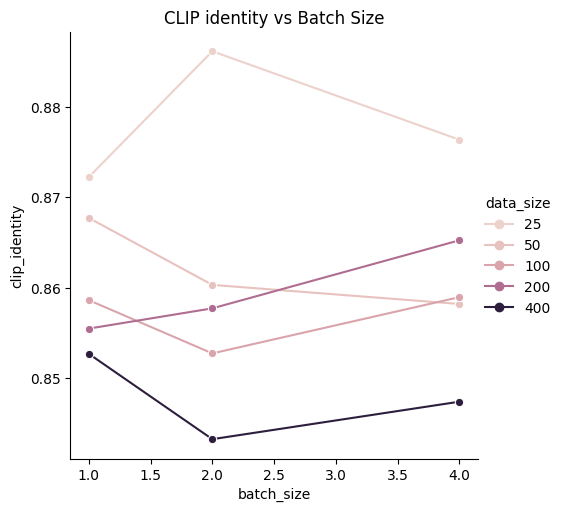

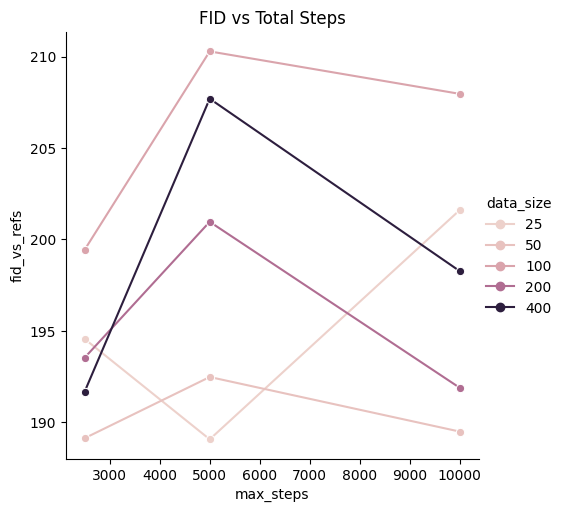

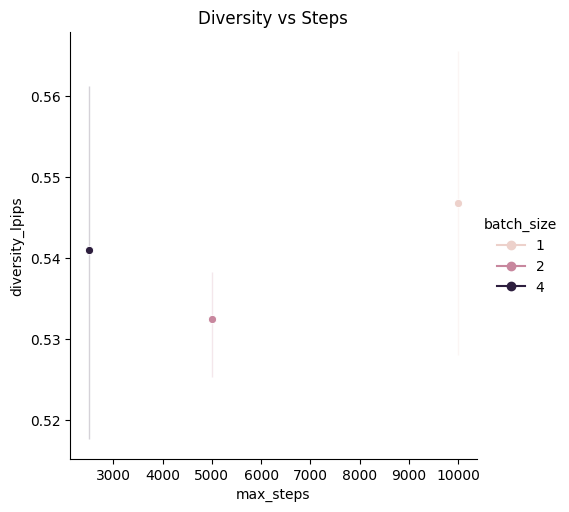

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

if not metrics_df.empty:
    sns.relplot(data=metrics_df, x='batch_size', y='clip_identity', hue='data_size', kind='line', marker='o')
    plt.title('CLIP identity vs Batch Size')
    plt.show()

    sns.relplot(data=metrics_df, x='max_steps', y='fid_vs_refs', hue='data_size', kind='line', marker='o')
    plt.title('FID vs Total Steps')
    plt.show()

    sns.relplot(data=metrics_df, x='max_steps', y='diversity_lpips', hue='batch_size', kind='line', marker='o')
    plt.title('Diversity vs Steps')
    plt.show()

## Notebook complete

- Trained LoRAs go to `outputs/loras/run_xx/` inside your Drive.
- Generated samples live in `outputs/generations/run_xx/`.
- Metrics summary is saved at `outputs/metrics/metrics_summary.csv`.

The final metrics table is included in this repository as `data/lora_metrics.csv` and analyzed in `Analysis.ipynb`.

In [3]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [7]:
import pandas as pd
from io import StringIO

html_string = """
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>run_id</th>
      <th>data_size</th>
      <th>batch_size</th>
      <th>max_steps</th>
      <th>epochs</th>
      <th>clip_identity</th>
      <th>lpips_identity</th>
      <th>fid_vs_refs</th>
      <th>diversity_lpips</th>
      <th>overfit_ratio</th>
      <th>num_eval_images</th>
    </tr>
  </thead>
  <tbody>
    <tr><th>0</th><td>run_01</td><td>400</td><td>4</td><td>2500</td><td>25</td><td>0.847405</td><td>0.526701</td><td>191.668517</td><td>0.546048</td><td>1.0</td><td>40</td></tr>
    <tr><th>1</th><td>run_02</td><td>400</td><td>2</td><td>5000</td><td>25</td><td>0.843261</td><td>0.523061</td><td>207.697964</td><td>0.528593</td><td>1.0</td><td>40</td></tr>
    <tr><th>2</th><td>run_03</td><td>400</td><td>1</td><td>10000</td><td>25</td><td>0.852696</td><td>0.523678</td><td>198.259703</td><td>0.547685</td><td>1.0</td><td>40</td></tr>
    <tr><th>3</th><td>run_04</td><td>200</td><td>4</td><td>2500</td><td>50</td><td>0.865243</td><td>0.508646</td><td>193.525229</td><td>0.496636</td><td>1.0</td><td>40</td></tr>
    <tr><th>4</th><td>run_05</td><td>200</td><td>2</td><td>5000</td><td>50</td><td>0.857724</td><td>0.508229</td><td>200.961178</td><td>0.520108</td><td>1.0</td><td>40</td></tr>
    <tr><th>5</th><td>run_06</td><td>200</td><td>1</td><td>10000</td><td>50</td><td>0.855486</td><td>0.508698</td><td>191.874799</td><td>0.523598</td><td>1.0</td><td>40</td></tr>
    <tr><th>6</th><td>run_07</td><td>100</td><td>4</td><td>2500</td><td>100</td><td>0.858960</td><td>0.515680</td><td>199.433648</td><td>0.532123</td><td>1.0</td><td>40</td></tr>
    <tr><th>7</th><td>run_08</td><td>100</td><td>2</td><td>5000</td><td>100</td><td>0.852743</td><td>0.518650</td><td>210.286582</td><td>0.536301</td><td>1.0</td><td>40</td></tr>
    <tr><th>8</th><td>run_09</td><td>100</td><td>1</td><td>10000</td><td>100</td><td>0.858628</td><td>0.518816</td><td>207.962131</td><td>0.522650</td><td>1.0</td><td>40</td></tr>
    <tr><th>9</th><td>run_10</td><td>50</td><td>4</td><td>2500</td><td>200</td><td>0.858208</td><td>0.536654</td><td>189.117265</td><td>0.564244</td><td>1.0</td><td>40</td></tr>
    <tr><th>10</th><td>run_11</td><td>50</td><td>2</td><td>5000</td><td>200</td><td>0.860318</td><td>0.517635</td><td>192.467056</td><td>0.537520</td><td>1.0</td><td>40</td></tr>
    <tr><th>11</th><td>run_12</td><td>50</td><td>1</td><td>10000</td><td>200</td><td>0.867717</td><td>0.527230</td><td>189.479020</td><td>0.559650</td><td>1.0</td><td>40</td></tr>
    <tr><th>12</th><td>run_13</td><td>25</td><td>4</td><td>2500</td><td>400</td><td>0.876365</td><td>0.529112</td><td>194.548333</td><td>0.565951</td><td>1.0</td><td>40</td></tr>
    <tr><th>13</th><td>run_14</td><td>25</td><td>2</td><td>5000</td><td>400</td><td>0.886142</td><td>0.504690</td><td>189.055962</td><td>0.539909</td><td>1.0</td><td>40</td></tr>
    <tr><th>14</th><td>run_15</td><td>25</td><td>1</td><td>10000</td><td>400</td><td>0.872235</td><td>0.521368</td><td>201.604504</td><td>0.580433</td><td>1.0</td><td>40</td></tr>
  </tbody>
</table>
"""

dfs = pd.read_html(StringIO(html_string))
metrics_df = dfs[0]

# Drop the index column pandas creates from the <th> row numbers
if metrics_df.columns[0] == 'Unnamed: 0' or str(metrics_df.columns[0]).isdigit():
    metrics_df = metrics_df.drop(columns=metrics_df.columns[0])

output_file = 'lora_metrics.csv'
metrics_df.to_csv(output_file, index=False)

print(f"Saved {output_file}: {metrics_df.shape[0]} rows, {metrics_df.shape[1]} columns")
print(f"Columns: {list(metrics_df.columns)}")
metrics_df

Saved lora_metrics.csv: 15 rows, 11 columns
Columns: ['run_id', 'data_size', 'batch_size', 'max_steps', 'epochs', 'clip_identity', 'lpips_identity', 'fid_vs_refs', 'diversity_lpips', 'overfit_ratio', 'num_eval_images']


,run_id,data_size,batch_size,max_steps,epochs,clip_identity,lpips_identity,fid_vs_refs,diversity_lpips,overfit_ratio,num_eval_images
0,run_01,400,4,2500,25,0.847405,0.526701,191.668517,0.546048,1.0,40
1,run_02,400,2,5000,25,0.843261,0.523061,207.697964,0.528593,1.0,40
2,run_03,400,1,10000,25,0.852696,0.523678,198.259703,0.547685,1.0,40
3,run_04,200,4,2500,50,0.865243,0.508646,193.525229,0.496636,1.0,40
4,run_05,200,2,5000,50,0.857724,0.508229,200.961178,0.520108,1.0,40
5,run_06,200,1,10000,50,0.855486,0.508698,191.874799,0.523598,1.0,40
6,run_07,100,4,2500,100,0.858960,0.515680,199.433648,0.532123,1.0,40
7,run_08,100,2,5000,100,0.852743,0.518650,210.286582,0.536301,1.0,40
8,run_09,100,1,10000,100,0.858628,0.518816,207.962131,0.522650,1.0,40
9,run_10,50,4,2500,200,0.858208,0.536654,189.117265,0.564244,1.0,40


In [11]:
import shutil
shutil.copy('lora_metrics.csv', '/content/drive/My Drive')
print("Done")

Done
